In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from pathlib import Path
import re
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
mask = '01'      # '01': hourly precipitation > 0.1 mm, '05': > 0.5 mm

# CESM2-LE hourly ensemble (10 members), ssp370 output of cesm2_hourly_precip_cover_calc.py --experiment ssp370
CESM2_DIR       = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_ens_hourly'
CESM2_THRESHOLD = {'01': 0.1, '05': 0.5}   # mm per hour, for each mask
CESM2_YEARS     = (2021, 2049)             # inclusive


In [5]:
import re

# hourly % of sea area with precipitation > threshold, one file per member; all members pooled per year
#cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/cesm2_sea_'+mask+'_1990-2050_30-60N_precip_count_sum.nc')['PRECT']
#cesm2 = cesm2[31:60,:]
thr = CESM2_THRESHOLD[mask]
pat = re.compile(r'^cesm2_hourly_precip_cover_(?P<member>[^_]+)_ssp370_30-60N\.nc$')
per_year = {}            # year -> list of hourly values (one array per member)
n_members = 0
for f in sorted(os.listdir(CESM2_DIR)):
    if not (m := pat.match(f)):
        continue
    ds = xr.open_dataset(os.path.join(CESM2_DIR, f), use_cftime=True)
    if 'wet_sea_pct' not in ds:
        raise ValueError(f'{f} has no wet_sea_pct (made by an older version): rerun cesm2_hourly_precip_cover_calc.py --experiment ssp370 --overwrite')
    da = ds['wet_sea_pct'].sel(threshold=thr, method='nearest')
    if abs(float(da.threshold) - thr) > 1e-9:
        raise ValueError(f'{f}: no threshold {thr} mm/h')
    yr = da.time.dt.year.values
    for y in range(CESM2_YEARS[0], CESM2_YEARS[1] + 1):
        per_year.setdefault(y, []).append(da.values[yr == y])
    n_members += 1
    print(f'CESM2 {m["member"]}: {int(((yr >= CESM2_YEARS[0]) & (yr <= CESM2_YEARS[1])).sum())} hours in {CESM2_YEARS[0]}-{CESM2_YEARS[1]}')

# (year, pooled hour) array; every member has the same hours per year, NaN-padded otherwise
years_c = sorted(per_year)
pooled = [np.concatenate(per_year[y]) for y in years_c]
n_max = max(v.size for v in pooled)
data = np.full((len(years_c), n_max), np.nan)
for i, v in enumerate(pooled):
    data[i, :v.size] = v
cesm2 = xr.DataArray(data, dims=('year', 'time'), coords={'year': years_c}, name='wet_sea_pct')   # % of sea area
print(f'\n{n_members} members pooled: {len(years_c)} years, {n_max} hours per year, > {thr} mm/h')


CESM2 1011.001: 128064 hours in 2021-2049
CESM2 1031.002: 128064 hours in 2021-2049
CESM2 1051.003: 128064 hours in 2021-2049
CESM2 1071.004: 128064 hours in 2021-2049
CESM2 1091.005: 128064 hours in 2021-2049
CESM2 1111.006: 128064 hours in 2021-2049
CESM2 1131.007: 128064 hours in 2021-2049
CESM2 1151.008: 128064 hours in 2021-2049
CESM2 1171.009: 128064 hours in 2021-2049
CESM2 1191.010: 128064 hours in 2021-2049

10 members pooled: 29 years, 44160 hours per year, > 0.1 mm/h


In [6]:

cesm2_tmean = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/tmean/cesm2_1990-2050_ensmean_30-60N_yearly_tmean.nc')['TREFHT']
#cesm2_tmean = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/tmean/cesm2_1990-2050_013_30-60N_yearly_tmean.nc')['TREFHT']
cesm2_tmean = cesm2_tmean[31:60,:,:]     # 2021-2049 (index 0 = 1990)
if cesm2_tmean.shape[0] != cesm2.sizes['year']:
    print(f'WARNING: {cesm2_tmean.shape[0]} temperature years vs {cesm2.sizes["year"]} precipitation years')
latitude = [30,60]

land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=cesm2_tmean.lat, lon=cesm2_tmean.lon)
cesm2_tmean_sea = cesm2_tmean.where(land_sea_cesm2 == 0, np.nan)
lat_weights = xr.DataArray(
    np.cos(np.deg2rad(land_sea_cesm2['lat'])),
    dims=['lat'],
    coords={'lat': land_sea_cesm2['lat']}
)
cesm2_tmean_sea_mean = cesm2_tmean_sea.weighted(lat_weights).mean(dim=["lat", "lon"])
cesm2_tmean_sea_diff = cesm2_tmean_sea_mean - cesm2_tmean_sea_mean[0]

## CESM2 

In [7]:
latitude = [30,60]

cesm2_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
cesm2_size = cesm2_size[0,:,:]
indexer = ((cesm2_size.lat>=latitude[0]) & (cesm2_size.lat<=latitude[1]))
cesm2_size = cesm2_size.where(indexer,drop=True)
# 5) Compute percentage of grid cells for each time
cesm2_sea = xr.where(cesm2_size == 0, 1, 0)
lat_weights = xr.DataArray(
    np.cos(np.deg2rad(cesm2_size['lat'])),
    dims=['lat'],
    coords={'lat': cesm2_size['lat']}
)
total_cells = cesm2_sea.weighted(lat_weights).sum()


percent_cesm2 = cesm2                       # already % of sea area (cos(lat)-weighted), pooled members per year
percent_cesm2_mean = percent_cesm2.mean(dim=['time'])
cesm2_lin = stats.linregress(cesm2_tmean_sea_mean,percent_cesm2_mean)

print(cesm2_lin)

LinregressResult(slope=-0.5146867233513207, intercept=24.310341536461195, rvalue=-0.7577233385960501, pvalue=1.9375391807883237e-06, stderr=0.08530637139053761, intercept_stderr=1.2056127847333948)


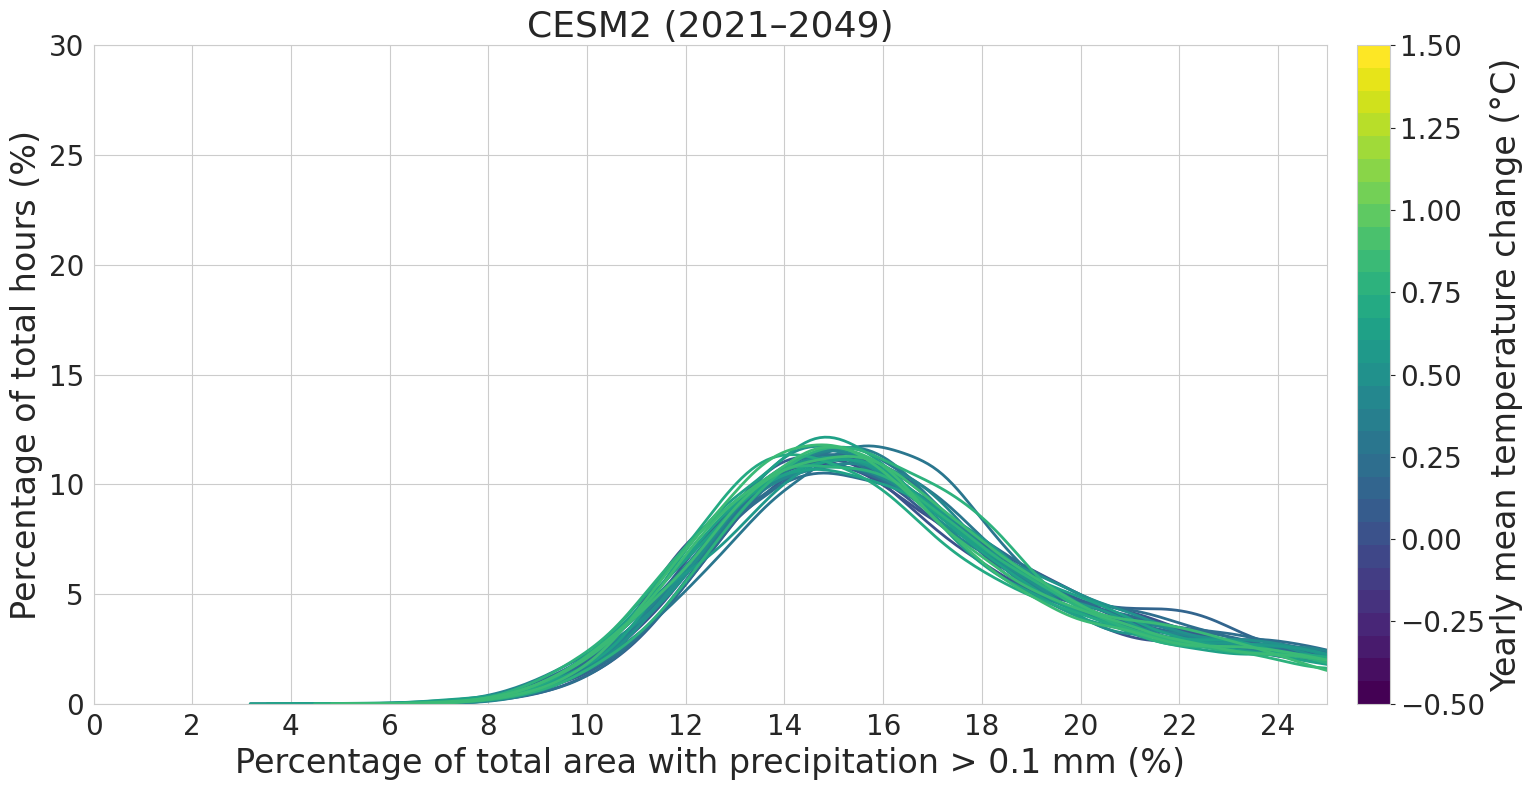

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Common x‐range + bin width
xmin, xmax = 0, 25
bin_width = 1.0

# 2) Year indices (0–29) and number of years
years = percent_cesm2.year.values
n_years = len(years)

# 3) Viridis colormap
temps = cesm2_tmean_sea_diff.values
cmap = plt.get_cmap('viridis', n_years)

norm = plt.Normalize(
    vmin=-0.5,
    vmax=1.5
)


fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")

# Prepare to record the total weight for each year
sum_weights = []

# 4) Plot each year's KDE
for i, (yr, temp) in enumerate(zip(years, temps)):
    vals = percent_cesm2.sel(year=yr).values.ravel()
    vals = vals[~np.isnan(vals)]
    # weights that sum to 100
    w = np.ones_like(vals) * (100.0 / vals.size)
    sum_weights.append(w.sum())  # this will be 100.0 for each year

    sns.kdeplot(
        x=vals,
        weights=w,
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=cmap(norm(temp)),
        legend=False
    )

# 5) Rescale from “percent per unit‐x” → “percent per 0.5%‐bin”
for line, total_w in zip(ax.get_lines(), sum_weights):
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * bin_width * total_w
    line.set_data(x_vals, y_scaled)

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

ticks = np.linspace(-0.5, 1.5, 9)

cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=ticks)
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)

# 7) polish & save
if mask == '01':
    xl = 'Percentage of total area with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 30)
elif mask == '02':
    xl = 'Percentage of total area with precipitation > 0.2 mm (%)'
    ax.set_ylim(0, 70)
elif mask == '05':
    xl = 'Percentage of total area with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 70)
    xmin, xmax = 0, 10

plt.xlim(xmin, xmax)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)
ax.set_xlabel(xl, fontsize=24)
ax.set_ylabel('Percentage of total hours (%)', fontsize=24)
ax.set_xlim(xmin, xmax)
ax.tick_params(axis='both', which='major', labelsize=20)
plt.title('CESM2 (2021–2049)', fontsize=26)
plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_sea_cesm2_histo_precip_coverage_'+mask+'_temp_ens.pdf', format='pdf',bbox_inches='tight')

plt.show()
